<a href="https://colab.research.google.com/github/thanhf16hehe-droid/tuan2_phanchithanh/blob/main/Bai_tap_MLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bài thực hành: MLP với dữ liệu ảnh — thí nghiệm mở rộng



### Mục tiêu và thiết kế thí nghiệm

1. So sánh MLP có 1, 2, 3 hidden layers theo số tham số, thời gian train, validation accuracy và test accuracy.
2. So sánh learning rate `1e-2`, `1e-3`, `1e-4`; xem learning curves và nhận xét.
3. So sánh batch size `32`, `128`, `512`; xem thời gian và kết quả.
4. Thêm `Dropout(0.3)` giữa các Dense layer; đối chiếu train/validation accuracy.
5. Thêm L2 qua `kernel_regularizer=tf.keras.regularizers.l2(...)`.
6. Tìm 20 ảnh test dự đoán sai có confidence cao nhất và phân tích.

**Nguyên tắc:** validation dùng để so sánh cấu hình; test chỉ dùng để báo cáo đánh giá cuối cho từng cấu hình đã định trước. Thời gian có thể khác đáng kể theo phần cứng/GPU.


## 1. Chuẩn bị thư viện và seed

In [1]:
import os, random, time, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU: []


## 2. Tải Fashion-MNIST và chia train/validation/test

Keras tải dữ liệu tự động. Bộ gốc gồm 60.000 ảnh train và 10.000 ảnh test. Tách 10.000 ảnh từ phần train ban đầu làm validation; test không tham gia chọn mô hình. Pixel được chuẩn hóa về [0, 1].

In [2]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
(x_all, y_all), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
VAL_SIZE = 10_000
x_train, y_train = x_all[:-VAL_SIZE], y_all[:-VAL_SIZE]
x_val, y_val = x_all[-VAL_SIZE:], y_all[-VAL_SIZE:]
x_train = x_train.astype("float32") / 255.0
x_val = x_val.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
print("Train", x_train.shape, "Validation", x_val.shape, "Test", x_test.shape)


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train (50000, 28, 28) Validation (10000, 28, 28) Test (10000, 28, 28)


## 3. Hàm tạo, huấn luyện và đánh giá MLP

Kiến trúc mặc định giữ 256 neuron mỗi hidden layer để so sánh độ sâu tương đối công bằng. Parameter count là tổng số tham số có thể học. Thời gian train chỉ tính `fit`, không tính đánh giá.

In [3]:
EPOCHS = 12
PATIENCE = 3
BATCH_BASE = 128
BASE_LR = 1e-3

def build_mlp(hidden_units=(256, 128), dropout=0.0, l2_strength=0.0, learning_rate=BASE_LR):
    reg = tf.keras.regularizers.l2(l2_strength) if l2_strength else None
    layers = [tf.keras.layers.Input(shape=(28, 28)), tf.keras.layers.Flatten()]
    for units in hidden_units:
        layers.append(tf.keras.layers.Dense(units, activation="relu", kernel_regularizer=reg))
        if dropout:
            layers.append(tf.keras.layers.Dropout(dropout))
    layers.append(tf.keras.layers.Dense(10, activation="softmax"))
    model = tf.keras.Sequential(layers)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def run_experiment(name, hidden_units=(256,128), learning_rate=BASE_LR, batch_size=BATCH_BASE,
                   dropout=0.0, l2_strength=0.0):
    tf.keras.backend.clear_session(); gc.collect()
    tf.keras.utils.set_random_seed(SEED)
    model = build_mlp(hidden_units, dropout, l2_strength, learning_rate)
    params = model.count_params()
    callbacks = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                restore_best_weights=True, verbose=0)]
    start = time.perf_counter()
    hist = model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=EPOCHS,
                     batch_size=batch_size, callbacks=callbacks, verbose=0, shuffle=True)
    train_seconds = time.perf_counter() - start
    val_loss, val_acc = model.evaluate(x_val, y_val, batch_size=batch_size, verbose=0)
    test_loss, test_acc = model.evaluate(x_test, y_test, batch_size=batch_size, verbose=0)
    result = {"name":name, "hidden_units":tuple(hidden_units), "params":params,
              "train_seconds":train_seconds, "best_epoch":int(np.argmin(hist.history["val_loss"])+1),
              "val_accuracy":float(val_acc), "test_accuracy":float(test_acc),
              "train_accuracy":float(hist.history["accuracy"][-1]), "history":hist.history,
              "model":model}
    return result

def show_curves(results, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for r in results:
        h=r["history"]; label=r["name"]
        axes[0].plot(h["loss"], label=label); axes[0].plot(h["val_loss"], linestyle="--", label=label+" val")
        axes[1].plot(h["accuracy"], label=label); axes[1].plot(h["val_accuracy"], linestyle="--", label=label+" val")
    axes[0].set_title("Loss theo epoch"); axes[1].set_title("Accuracy theo epoch")
    for ax in axes: ax.set_xlabel("Epoch"); ax.grid(True, alpha=.25); ax.legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

def result_table(results):
    return pd.DataFrame([{k:r[k] for k in ["name","params","train_seconds","best_epoch","train_accuracy","val_accuracy","test_accuracy"]} for r in results])


## Bài 1 — So sánh số hidden layers

Mỗi hidden layer có 256 neuron. Vì vậy cấu hình sâu hơn làm tăng số tham số và chi phí tính toán. Bảng dùng accuracy trên validation và test cùng số tham số và thời gian huấn luyện.

,name,params,train_seconds,best_epoch,train_accuracy,val_accuracy,test_accuracy
0,1 hidden layer,203530,41.4266,9,0.9192,0.8797,0.8719
1,2 hidden layers,269322,41.0581,6,0.9149,0.8782,0.8743
2,3 hidden layers,335114,33.9456,4,0.9054,0.8730,0.8676


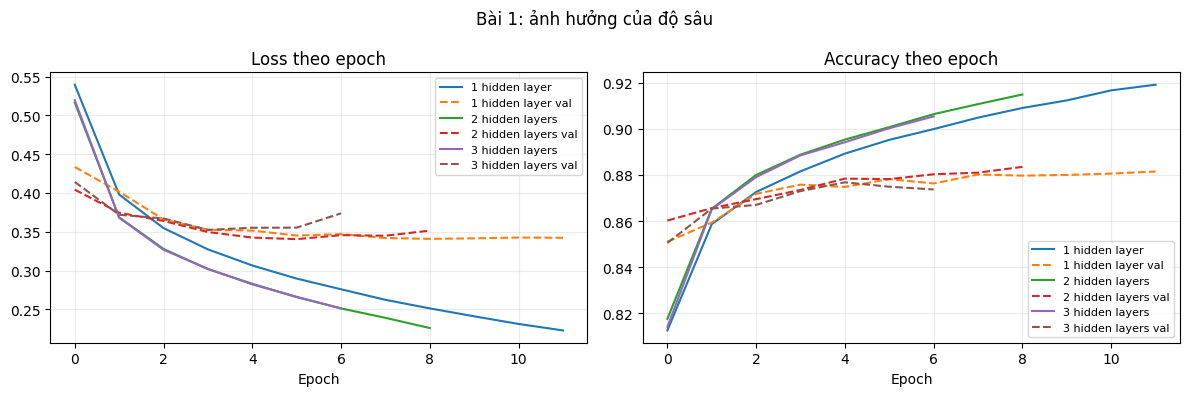

In [4]:
arch_results = [
    run_experiment("1 hidden layer", (256,)),
    run_experiment("2 hidden layers", (256, 256)),
    run_experiment("3 hidden layers", (256, 256, 256)),
]
display(result_table(arch_results).round(4))
show_curves(arch_results, "Bài 1: ảnh hưởng của độ sâu")


**Gợi ý nhận xét:** Số tham số lớn hơn thường làm tăng khả năng biểu diễn, nhưng không đảm bảo test accuracy luôn cao hơn. So sánh validation/test và thời gian thực đo; ghi nhận nếu chênh lệch train–validation lớn.

## Bài 2 — So sánh learning rate

Giữ kiến trúc 2 hidden layers và batch size 128, chỉ thay learning rate.

,name,params,train_seconds,best_epoch,train_accuracy,val_accuracy,test_accuracy
0,lr=0.01,235146,22.0912,2,0.8763,0.8558,0.8499
1,lr=0.001,235146,39.7791,8,0.9224,0.8805,0.8758
2,lr=0.0001,235146,45.2484,12,0.8906,0.8757,0.8688


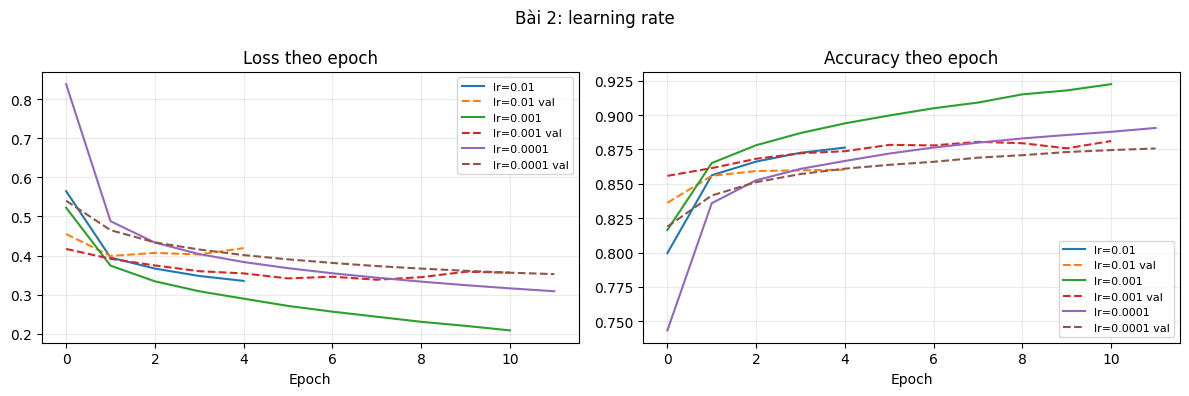

In [5]:
lr_results = [run_experiment(f"lr={lr:g}", (256,128), learning_rate=lr) for lr in (1e-2, 1e-3, 1e-4)]
display(result_table(lr_results).round(4))
show_curves(lr_results, "Bài 2: learning rate")


**Gợi ý nhận xét:** Learning rate quá lớn có thể khiến loss dao động hoặc không hội tụ; quá nhỏ thường học chậm trong số epoch giới hạn. Đọc cả loss và accuracy của train/validation, không chỉ epoch cuối.

## Bài 3 — So sánh batch size

Giữ kiến trúc và learning rate, so sánh batch 32, 128, 512. Thời gian phụ thuộc phần cứng và cách TensorFlow nạp batch.

,name,params,train_seconds,best_epoch,train_accuracy,val_accuracy,test_accuracy
0,batch=32,235146,64.3889,4,0.9071,0.8770,0.8683
1,batch=128,235146,40.2006,8,0.9224,0.8805,0.8758
2,batch=512,235146,24.8377,7,0.9072,0.8771,0.8713


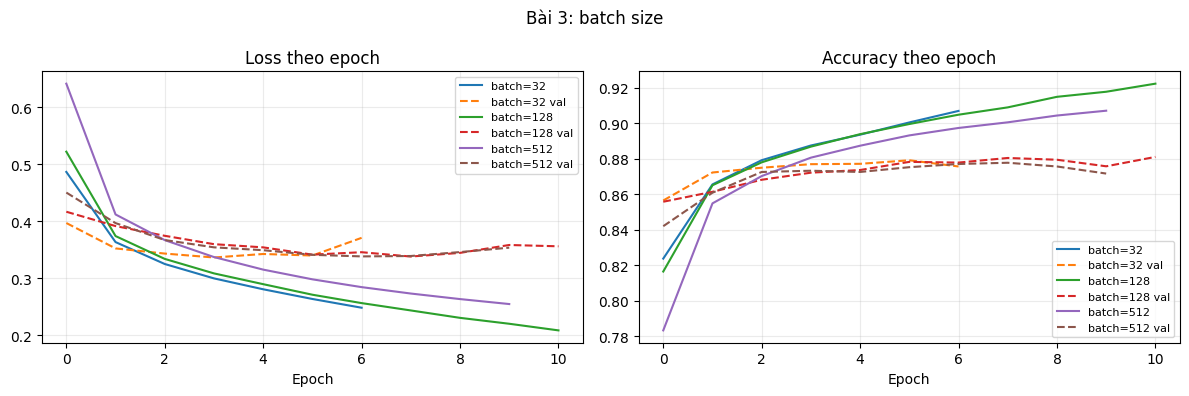

In [6]:
batch_results = [run_experiment(f"batch={bs}", (256,128), batch_size=bs) for bs in (32,128,512)]
display(result_table(batch_results).round(4))
show_curves(batch_results, "Bài 3: batch size")


**Gợi ý nhận xét:** Batch nhỏ có nhiều bước cập nhật trong mỗi epoch và có thể mất nhiều thời gian hơn; batch lớn giảm số bước nhưng có thể cần điều chỉnh learning rate và bộ nhớ. Kết luận dựa trên thời gian và accuracy thực đo trên phiên Colab của bạn.

## Bài 4 — Dropout(0.3)

Thêm Dropout sau mỗi hidden Dense layer. So sánh train/validation accuracy và đường cong với baseline 2 lớp. Dropout chỉ hoạt động khi train.

,name,params,train_seconds,best_epoch,train_accuracy,val_accuracy,test_accuracy
0,2 hidden layers,269322,41.0581,6,0.9149,0.8782,0.8743
1,Dropout 0.3,235146,46.2158,12,0.8932,0.8837,0.8745


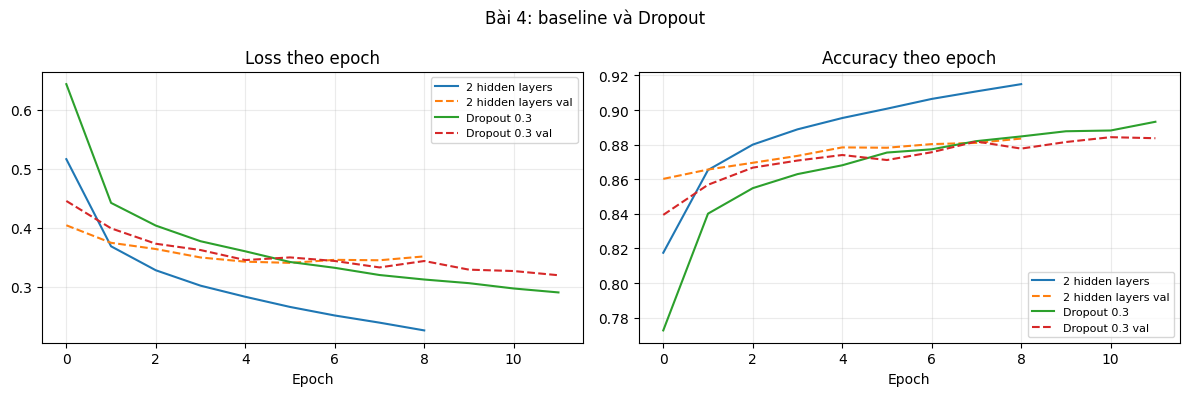

In [7]:
baseline = arch_results[1]
dropout_result = run_experiment("Dropout 0.3", (256,128), dropout=0.3)
display(result_table([baseline, dropout_result]).round(4))
show_curves([baseline, dropout_result], "Bài 4: baseline và Dropout")


**Gợi ý nhận xét:** Dropout thường làm giảm khả năng ghi nhớ dữ liệu train, nên train accuracy có thể thấp hơn; nếu overfitting giảm, khoảng cách train/validation có thể thu hẹp. Kết quả cụ thể tùy dữ liệu và số epoch.

## Bài 5 — L2 regularization

Dùng `kernel_regularizer=tf.keras.regularizers.l2(1e-4)` trong các Dense layer ẩn. Loss huấn luyện bao gồm thêm penalty L2.

,name,params,train_seconds,best_epoch,train_accuracy,val_accuracy,test_accuracy
0,2 hidden layers,269322,41.0581,6,0.9149,0.8782,0.8743
1,L2=0.0001,235146,37.9639,6,0.9073,0.8746,0.8684


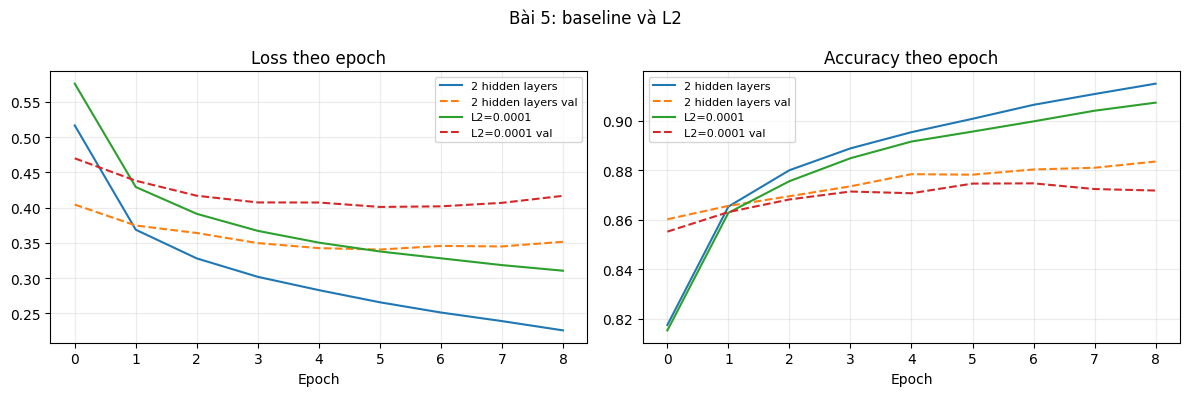

In [8]:
L2_STRENGTH = 1e-4
l2_result = run_experiment(f"L2={L2_STRENGTH:g}", (256,128), l2_strength=L2_STRENGTH)
display(result_table([baseline, l2_result]).round(4))
show_curves([baseline, l2_result], "Bài 5: baseline và L2")


**Gợi ý nhận xét:** L2 phạt trọng số lớn, giúp hạn chế mô hình quá phức tạp. So sánh validation/test accuracy và train–validation gap; regularization quá mạnh cũng có thể gây underfitting.

## Bài 6 — 20 dự đoán sai có confidence cao nhất

Chọn mô hình baseline 2 hidden layers và tính confidence là xác suất softmax lớn nhất. Trong tập dự đoán sai, sắp xếp giảm dần theo confidence để tìm 20 trường hợp mô hình sai nhưng rất tự tin. Nếu mô hình không có đủ 20 lỗi thì hiển thị tất cả.

Có 1257 dự đoán sai; hiển thị 20 lỗi confidence cao nhất.


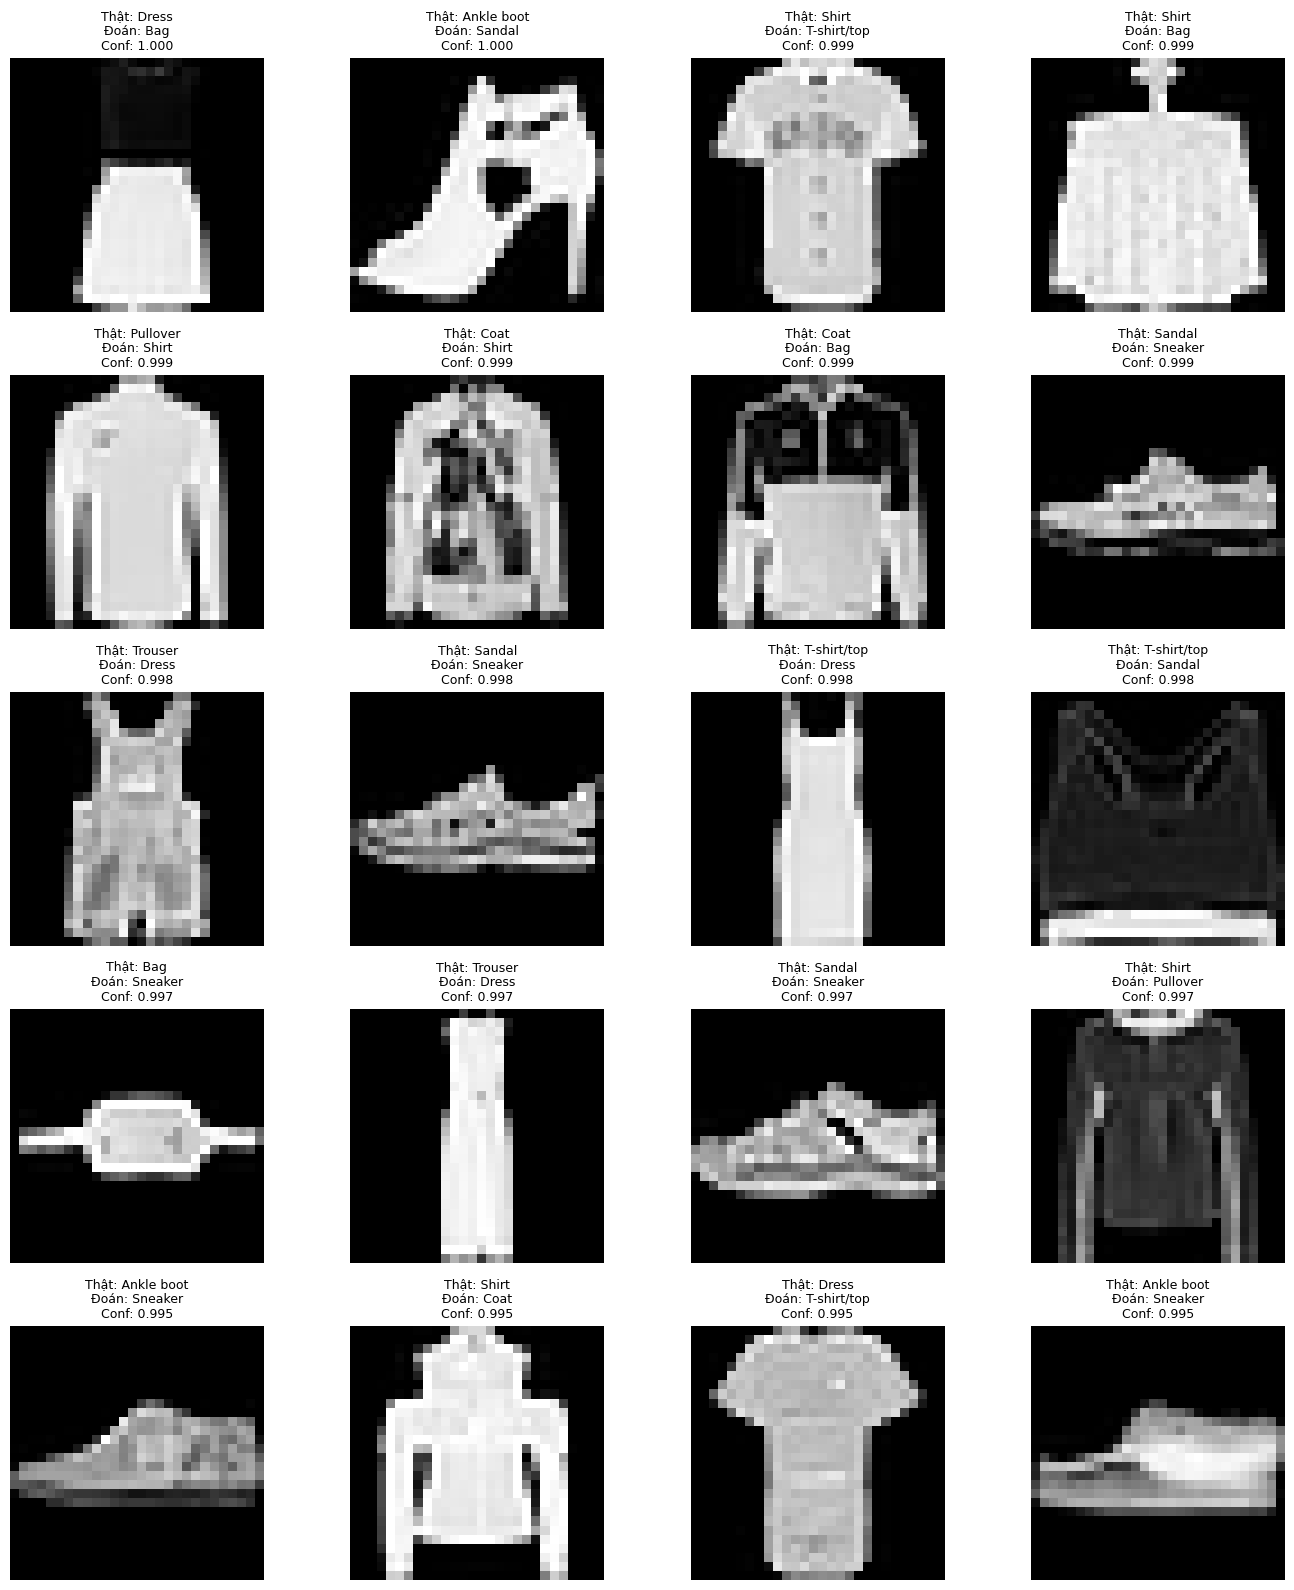

,index,nhãn_thật,dự_đoán,confidence
0,4394,Dress,Bag,0.999936
1,5946,Ankle boot,Sandal,0.999813
2,2856,Shirt,T-shirt/top,0.999192
3,9445,Shirt,Bag,0.999102
4,9574,Pullover,Shirt,0.999091
5,324,Coat,Shirt,0.998981
6,7349,Coat,Bag,0.998880
7,4405,Sandal,Sneaker,0.998580
8,3974,Trouser,Dress,0.998425
9,8292,Sandal,Sneaker,0.998312


In [9]:
error_model = baseline["model"]
prob = error_model.predict(x_test, batch_size=BATCH_BASE, verbose=0)
pred = prob.argmax(axis=1)
confidence = prob.max(axis=1)
wrong = np.flatnonzero(pred != y_test)
top_wrong = wrong[np.argsort(confidence[wrong])[::-1][:20]]
print(f"Có {len(wrong)} dự đoán sai; hiển thị {len(top_wrong)} lỗi confidence cao nhất.")

cols=4; rows=int(np.ceil(len(top_wrong)/cols))
fig, axes=plt.subplots(rows, cols, figsize=(14, 3.2*rows)); axes=np.array(axes).reshape(-1)
for ax, i in zip(axes, top_wrong):
    ax.imshow(x_test[i], cmap="gray"); ax.axis("off")
    ax.set_title(f"Thật: {class_names[y_test[i]]}\nĐoán: {class_names[pred[i]]}\nConf: {confidence[i]:.3f}", fontsize=9)
for ax in axes[len(top_wrong):]: ax.axis("off")
plt.tight_layout(); plt.show()

error_df = pd.DataFrame({"index":top_wrong, "nhãn_thật":[class_names[y_test[i]] for i in top_wrong],
                         "dự_đoán":[class_names[pred[i]] for i in top_wrong],
                         "confidence":confidence[top_wrong]})
display(error_df)


### Hướng dẫn phân tích ảnh lỗi

Quan sát hình dạng, góc nhìn, độ mờ và phần bị che. Fashion-MNIST có ảnh nhỏ, xám, nền đơn giản; một số lớp như Shirt, T-shirt/top, Pullover và Coat có hình dáng gần nhau. MLP làm phẳng ảnh thành vector nên không giữ rõ quan hệ không gian như CNN. Với từng mẫu, ghi rõ đặc điểm ảnh khiến nhãn thật và nhãn dự đoán dễ bị nhầm. Confidence cao nhưng sai là dấu hiệu mô hình có thể quá tự tin, không đồng nghĩa dự đoán đúng.

## Bảng đánh giá bổ sung: lớp thường bị nhầm

Confusion matrix và báo cáo phân loại được tạo cho baseline để hỗ trợ phần báo cáo.

Hai hướng nhầm lẫn nhiều nhất (nhãn thật → dự đoán):
- Shirt → T-shirt/top: 153
- Pullover → Coat: 136


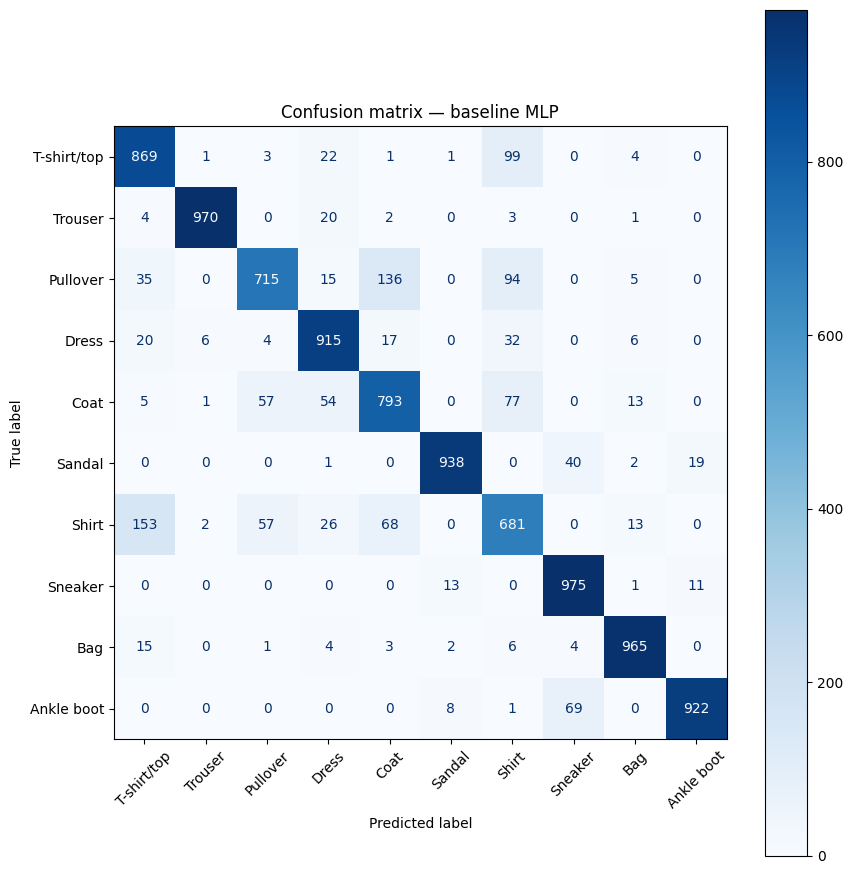

              precision    recall  f1-score   support

 T-shirt/top     0.7893    0.8690    0.8272      1000
     Trouser     0.9898    0.9700    0.9798      1000
    Pullover     0.8542    0.7150    0.7784      1000
       Dress     0.8657    0.9150    0.8896      1000
        Coat     0.7775    0.7930    0.7851      1000
      Sandal     0.9751    0.9380    0.9562      1000
       Shirt     0.6858    0.6810    0.6834      1000
     Sneaker     0.8961    0.9750    0.9339      1000
         Bag     0.9554    0.9650    0.9602      1000
  Ankle boot     0.9685    0.9220    0.9447      1000

    accuracy                         0.8743     10000
   macro avg     0.8757    0.8743    0.8739     10000
weighted avg     0.8757    0.8743    0.8739     10000



In [10]:
cm = confusion_matrix(y_test, pred)
cm_no_diag = cm.copy(); np.fill_diagonal(cm_no_diag, 0)
top_pairs = [(np.unravel_index(i, cm_no_diag.shape)[0], np.unravel_index(i, cm_no_diag.shape)[1], cm_no_diag.flat[i])
             for i in np.argsort(cm_no_diag, axis=None)[-2:][::-1]]
print("Hai hướng nhầm lẫn nhiều nhất (nhãn thật → dự đoán):")
for a,b,n in top_pairs: print(f"- {class_names[a]} → {class_names[b]}: {n}")
fig, ax = plt.subplots(figsize=(9,9))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", xticks_rotation=45, values_format="d")
plt.title("Confusion matrix — baseline MLP"); plt.tight_layout(); plt.show()
print(classification_report(y_test, pred, target_names=class_names, digits=4))


# Báo cáo ngắn (8 yêu cầu)

Hoàn thành bảng dưới đây sau khi chạy các ô. Các dấu ngoặc vuông là chỗ cần điền/diễn giải từ kết quả thực tế, không phải số liệu giả.

1. **Kiến trúc mô hình:** baseline gồm 2 hidden layers (256, 128 neuron), ReLU; đầu ra 10 neuron softmax. Tổng số tham số: lấy từ bảng Bài 1.
2. **Optimizer, loss, learning rate, batch size:** Adam; sparse categorical crossentropy; learning rate `1e-3`; batch size `128` (baseline).
3. **Epoch tốt nhất:** lấy cột `best_epoch` cho baseline. EarlyStopping theo dõi `val_loss` và khôi phục trọng số tốt nhất.
4. **Training/validation learning curves:** chèn/diễn giải các biểu đồ ở Bài 1–5; nêu xu hướng loss và accuracy.
5. **Test accuracy:** lấy kết quả baseline trong bảng Bài 1; có thể nêu thêm các cấu hình khác nhưng phân biệt rõ.
6. **Hai cặp lớp bị nhầm nhiều nhất:** lấy hai dòng do ô confusion matrix in ra (theo hướng nhãn thật → dự đoán).
7. **Underfitting/overfitting:** dựa vào khoảng cách train/validation accuracy và xu hướng train/validation loss. Nêu bằng chứng cụ thể từ đồ thị.
8. **Một thay đổi đã thử và kết quả:** chọn Dropout, L2, learning rate, batch size hoặc độ sâu; trích số liệu baseline và cấu hình thay đổi từ bảng, sau đó nhận xét.

**Mẫu kết luận:** “Trong thí nghiệm này, cấu hình [..] đạt validation accuracy [..] và test accuracy [..]. So với baseline, [thay đổi] làm [tăng/giảm] test accuracy [..] và [thu hẹp/mở rộng] khoảng cách train–validation. Kết quả có thể thay đổi theo GPU/phiên chạy; test accuracy chỉ được dùng để báo cáo, không dùng chọn cấu hình.”
